In [1]:
# Cell 1 — Import library
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cell 2 — Load dataset
df = pd.read_csv("../data/processed/customer_support_tickets_clean.csv")

In [3]:
# Cell 3 — Data Quality Checks

# 1. Count missing satisfaction values
print(
    "Missing values:",
    df["Customer Satisfaction Rating"].isna().sum()
)


# 2. Show distinct non-missing values
print(
    "Unique values:",
    sorted(df["Customer Satisfaction Rating"].dropna().unique())
)

# 3. Confirm numeric type
print(
    "Data type:",
    df["Customer Satisfaction Rating"].dtype
)

# 4. Show invalid values outside 1–5
invalid = df[
    (df["Customer Satisfaction Rating"] < 1) |
    (df["Customer Satisfaction Rating"] > 5)
]

print("Invalid values:")
print(invalid["Customer Satisfaction Rating"])

Missing values: 5700
Unique values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
Data type: float64
Invalid values:
Series([], Name: Customer Satisfaction Rating, dtype: float64)


In [4]:
# Cell 4 — Average Satisfaction by Ticket Type

avg_satisfaction = (
    df.groupby("Ticket Type")["Customer Satisfaction Rating"]
      .mean()
      .sort_values()
)

print(avg_satisfaction)

Ticket Type
Refund Request          2.934564
Technical Issue         2.958621
Product Inquiry         3.016886
Billing Inquiry         3.027574
Cancellation Request    3.029070
Name: Customer Satisfaction Rating, dtype: float64


In [5]:
# Cell 5 — Classify Performance

def classify_performance(rating):
    if rating < 3:
        return "Poor"
    elif rating < 4:
        return "Average"
    else:
        return "Good"

performance = avg_satisfaction.apply(classify_performance)

print(performance)

Ticket Type
Refund Request             Poor
Technical Issue            Poor
Product Inquiry         Average
Billing Inquiry         Average
Cancellation Request    Average
Name: Customer Satisfaction Rating, dtype: object


In [6]:
# Cell 6 — Highest and Lowest Satisfaction Categories

highest = avg_satisfaction.idxmax()
lowest = avg_satisfaction.idxmin()

print(
    "Highest satisfaction:",
    highest,
    "-",
    round(avg_satisfaction[highest], 2)
)

print(
    "Lowest satisfaction:",
    lowest,
    "-",
    round(avg_satisfaction[lowest], 2)
)

difference = (
    avg_satisfaction[highest]
    - avg_satisfaction[lowest]
)

print(
    "Difference:",
    round(difference, 2)
)

Highest satisfaction: Cancellation Request - 3.03
Lowest satisfaction: Refund Request - 2.93
Difference: 0.09


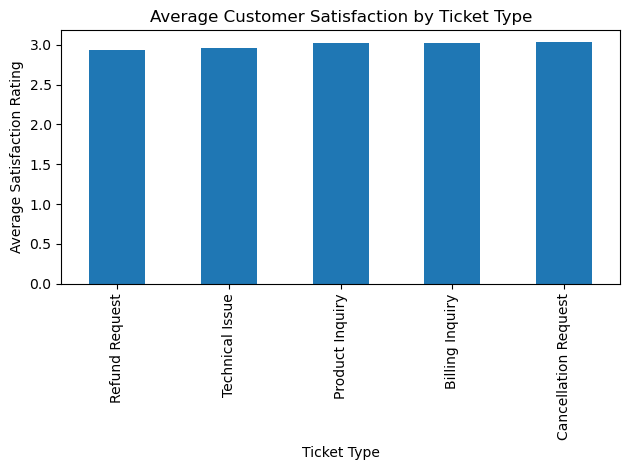

In [7]:
# Cell 7 — Visualization

avg_satisfaction.plot(
    kind="bar",
    title="Average Customer Satisfaction by Ticket Type"
)

plt.xlabel("Ticket Type")
plt.ylabel("Average Satisfaction Rating")
plt.tight_layout()
plt.show()


### Customer Satisfaction Analysis

**Lowest-satisfaction category:** Refund request — 2.93

**Highest-satisfaction category:** Cancellation request — 3.03

**Difference between highest and lowest:** 0.09 points

### Key observations

- Refund requests have the lowest average customer satisfaction rating,
  with an average score of 2.93.

- Cancellation requests have the highest average customer satisfaction
  rating, with an average score of 3.03.

- Average satisfaction is very similar across all five ticket types.
  The difference between the highest and lowest category is only
  0.09 points on a 1–5 scale.

- Refund requests and technical issues have averages below 3.0, while
  product inquiries, billing inquiries, and cancellation requests are
  slightly above 3.0.

### Business interpretation

No ticket type clearly stands out as having substantially better or worse
customer satisfaction. Satisfaction is clustered around 3.0 for every
category.

Refund requests have the lowest observed average satisfaction, but the
difference from the other categories is small. Therefore, the results do
not support concluding that one ticket category alone is responsible for
poor customer experience.

Further analysis of resolution time, ticket priority, unresolved tickets,
and other operational factors is needed to identify whether specific
support processes are associated with lower satisfaction.

### Limitations

- 5,700 tickets have missing Customer Satisfaction Rating values, so the
  averages are based only on tickets with available satisfaction scores.

- Average satisfaction alone cannot explain why customers gave particular
  ratings.

- The 0.09-point difference between the highest and lowest categories is
  small, and this analysis does not test whether that difference is
  statistically significant.customer satisfaction.

Limitations:
- The average satisfaction alone does not prove the cause of poor performance